# 03 — Branch D dimension engineering

This notebook implements the first level of the dimension-first clustering strategy for **Branch D — In Education**.

It converts theoretically selected survey responses into five transparent, equally interpretable dimension scores:

1. Economic resources
2. Human capital and educational trajectory
3. Career direction and transition readiness
4. Social capital and belonging
5. Agency and study engagement

The notebook uses only the 191 validated new-structure Branch D respondents. It does **not** create the final youth clusters. Its purpose is to document, construct and validate the indicators that will later receive equal influence in integrated clustering.

Important principles:

- all component mappings are explicit and auditable;
- nominal categories are never given arbitrary ordinal ranks;
- formative resource/readiness indices are not judged using Cronbach's alpha;
- reliability is shown only as a diagnostic for the reflective agency scale;
- scores are calculated when at least 60% of their components are observed;
- every score runs from 0 to 100, with higher values indicating more of the dimension named.

In [1]:
from __future__ import annotations

import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 120)
pd.set_option("display.max_rows", 160)

VALUES_FILE = Path("outputs/nysc_survey_cleaned_values.csv")
LABELS_FILE = Path("outputs/nysc_survey_cleaned_labels.csv")
OUTPUT_DIR = Path("outputs/branch_d_dimensions")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MIN_COMPONENT_COVERAGE = 0.60
EXPECTED_BRANCH_D_RECORDS = 191

for path in [VALUES_FILE, LABELS_FILE]:
    assert path.exists(), f"Required input is missing: {path.resolve()}"

print("Output directory:", OUTPUT_DIR.resolve())

Output directory: /Users/vimashafernando/Desktop/ClusterRP/outputs/branch_d_dimensions


## 1. Load the validated Branch D cohort

The final analysis branch—not the initial C20 route—controls inclusion. Legacy records without translated final-route metadata remain outside this analysis.

In [2]:
values_all = pd.read_csv(VALUES_FILE, low_memory=False)
labels_all = pd.read_csv(LABELS_FILE, low_memory=False)

strict_mask = (
    values_all["branch"].eq("D")
    & values_all["branch_routing_source"].eq("translated_final_active_branch")
)
values = values_all.loc[strict_mask].reset_index(drop=True)
labels = labels_all.loc[strict_mask].reset_index(drop=True)

assert len(values) == EXPECTED_BRANCH_D_RECORDS
assert values["respondent_id"].is_unique
assert values["branch"].eq("D").all()

display(pd.Series({
    "validated_branch_d_records": len(values),
    "unique_respondents": values["respondent_id"].nunique(),
    "initial_route_differs_from_final_d": int(values["branch_changed"].astype(bool).sum()),
}).to_frame("count"))

,count
validated_branch_d_records,191
unique_respondents,191
initial_route_differs_from_final_d,0


## 2. Component specification

Each component below is normalized to 0–1 before aggregation. Mappings represent a theory-defined condition—not an assumed numeric ordering of nominal categories.

The five indices are formative except `agency_study_engagement`, whose three SDT-oriented items are also examined as a reflective-scale diagnostic.

In [3]:
DIMENSION_COMPONENTS = {
    "economic_resources": [
        "income_resources",
        "working_household_share",
        "low_household_unemployment",
        "freedom_from_primary_earner_burden",
        "education_funding_security",
    ],
    "human_capital_trajectory": [
        "current_education_stage",
        "expected_education_level",
        "work_exposure_while_studying",
    ],
    "career_transition_readiness": [
        "transition_plan_present",
        "already_searching_for_work",
        "ideal_work_direction_defined",
        "ideal_sector_defined",
        "study_career_alignment",
    ],
    "social_capital_belonging": [
        "employment_network_strength",
        "supported_education_access",
        "institutional_belonging",
    ],
    "agency_study_engagement": [
        "autonomous_study_motivation",
        "study_autonomy",
        "study_competence",
    ],
}

COMPONENT_MANIFEST = [
    {
        "component": "income_resources", "dimension": "economic_resources",
        "source_variables": "household_income", "construction": "(income band - 1) / 4; code 99 is missing",
        "high_value_meaning": "Higher household income resources", "index_type": "formative",
    },
    {
        "component": "working_household_share", "dimension": "economic_resources",
        "source_variables": "household_workers; household_size", "construction": "workers / household size, clipped to 0–1",
        "high_value_meaning": "Larger share of household members working", "index_type": "formative",
    },
    {
        "component": "low_household_unemployment", "dimension": "economic_resources",
        "source_variables": "household_unemployed; household_size", "construction": "1 - unemployed / household size, clipped to 0–1",
        "high_value_meaning": "Lower household unemployment burden", "index_type": "formative",
    },
    {
        "component": "freedom_from_primary_earner_burden", "dimension": "economic_resources",
        "source_variables": "primary_earner_status", "construction": "no=1, shared=0.5, yes=0",
        "high_value_meaning": "Less personal responsibility for primary household income", "index_type": "formative",
    },
    {
        "component": "education_funding_security", "dimension": "economic_resources",
        "source_variables": "edu_funding_source",
        "construction": "government/free, scholarship, family or employer funded=1; own earnings=0; other=missing",
        "high_value_meaning": "Education funded without dependence on respondent's current earnings", "index_type": "formative",
    },
    {
        "component": "current_education_stage", "dimension": "human_capital_trajectory",
        "source_variables": "edu_status; highest_edu_completed",
        "construction": "theory-defined education-stage map; completed uses observed highest qualification when available",
        "high_value_meaning": "More advanced current/completed educational stage", "index_type": "formative",
    },
    {
        "component": "expected_education_level", "dimension": "human_capital_trajectory",
        "source_variables": "expected_highest_edu_d", "construction": "(expected education code - 1) / 6",
        "high_value_meaning": "Higher expected educational attainment", "index_type": "formative",
    },
    {
        "component": "work_exposure_while_studying", "dimension": "human_capital_trajectory",
        "source_variables": "worked_while_studying", "construction": "yes=1, no=0",
        "high_value_meaning": "Prior work exposure during education", "index_type": "formative",
    },
    {
        "component": "transition_plan_present", "dimension": "career_transition_readiness",
        "source_variables": "plans_after_education",
        "construction": "job, further education or business plan=1; stay home or do not know=0",
        "high_value_meaning": "Concrete education-to-work/learning transition plan", "index_type": "formative",
    },
    {
        "component": "already_searching_for_work", "dimension": "career_transition_readiness",
        "source_variables": "already_job_searching", "construction": "yes=1, no=0",
        "high_value_meaning": "Active preparation for the work transition", "index_type": "formative",
    },
    {
        "component": "ideal_work_direction_defined", "dimension": "career_transition_readiness",
        "source_variables": "ideal_work_type", "construction": "defined work type=1; not sure or does not wish to work=0",
        "high_value_meaning": "Clear preferred work arrangement", "index_type": "formative",
    },
    {
        "component": "ideal_sector_defined", "dimension": "career_transition_readiness",
        "source_variables": "ideal_sector", "construction": "defined sector=1; not sure=0",
        "high_value_meaning": "Clear preferred employment sector", "index_type": "formative",
    },
    {
        "component": "study_career_alignment", "dimension": "career_transition_readiness",
        "source_variables": "study_field_preference; ideal_sector",
        "construction": "1 when study field maps to preferred sector family; 0 when both observed but not aligned",
        "high_value_meaning": "Study field and preferred employment sector are aligned", "index_type": "formative",
    },
    {
        "component": "employment_network_strength", "dimension": "social_capital_belonging",
        "source_variables": "employment_network_quality", "construction": "(4 - code) / 3",
        "high_value_meaning": "Stronger useful employment contacts", "index_type": "formative",
    },
    {
        "component": "supported_education_access", "dimension": "social_capital_belonging",
        "source_variables": "social_capital_in_edu_access",
        "construction": "family/contact/employer/government guidance=1; entirely own initiative=0",
        "high_value_meaning": "Access supported by social or institutional connections", "index_type": "formative",
    },
    {
        "component": "institutional_belonging", "dimension": "social_capital_belonging",
        "source_variables": "relatedness_at_institution", "construction": "(4 - code) / 3",
        "high_value_meaning": "Stronger connection and belonging at institution", "index_type": "formative",
    },
    {
        "component": "autonomous_study_motivation", "dimension": "agency_study_engagement",
        "source_variables": "study_motivation_type", "construction": "(5 - code) / 4",
        "high_value_meaning": "More autonomous/intrinsic rather than amotivated study regulation", "index_type": "reflective_diagnostic",
    },
    {
        "component": "study_autonomy", "dimension": "agency_study_engagement",
        "source_variables": "autonomy_in_study", "construction": "(4 - code) / 3",
        "high_value_meaning": "Greater perceived choice and control in study", "index_type": "reflective_diagnostic",
    },
    {
        "component": "study_competence", "dimension": "agency_study_engagement",
        "source_variables": "competence_in_study_field", "construction": "(4 - code) / 3",
        "high_value_meaning": "Greater perceived capability in study field", "index_type": "reflective_diagnostic",
    },
]

component_manifest = pd.DataFrame(COMPONENT_MANIFEST)
assert set(component_manifest["component"]) == set(sum(DIMENSION_COMPONENTS.values(), []))
component_manifest.to_csv(OUTPUT_DIR / "branch_d_dimension_manifest.csv", index=False)
display(component_manifest)

,component,dimension,source_variables,construction,high_value_meaning,index_type
0,income_resources,economic_resources,household_income,(income band - 1) / 4; code 99 is missing,Higher household income resources,formative
1,working_household_share,economic_resources,household_workers; household_size,"workers / household size, clipped to 0–1",Larger share of household members working,formative
2,low_household_unemployment,economic_resources,household_unemployed; household_size,"1 - unemployed / household size, clipped to 0–1",Lower household unemployment burden,formative
3,freedom_from_primary_earner_burden,economic_resources,primary_earner_status,"no=1, shared=0.5, yes=0",Less personal responsibility for primary house...,formative
4,education_funding_security,economic_resources,edu_funding_source,"government/free, scholarship, family or employ...",Education funded without dependence on respond...,formative
5,current_education_stage,human_capital_trajectory,edu_status; highest_edu_completed,theory-defined education-stage map; completed ...,More advanced current/completed educational stage,formative
6,expected_education_level,human_capital_trajectory,expected_highest_edu_d,(expected education code - 1) / 6,Higher expected educational attainment,formative
7,work_exposure_while_studying,human_capital_trajectory,worked_while_studying,"yes=1, no=0",Prior work exposure during education,formative
8,transition_plan_present,career_transition_readiness,plans_after_education,"job, further education or business plan=1; sta...",Concrete education-to-work/learning transition...,formative
9,already_searching_for_work,career_transition_readiness,already_job_searching,"yes=1, no=0",Active preparation for the work transition,formative


## 3. Construct normalized components

Mappings below are deliberately visible in code. Unexpected categories produce missing values and are reported rather than silently forced into a score.

In [4]:
def numeric(series):
    return pd.to_numeric(series, errors="coerce")


def binary_yes_no(series):
    return series.astype("string").str.lower().map({"yes": 1.0, "no": 0.0})


def clipped_ratio(numerator, denominator):
    result = numeric(numerator) / numeric(denominator).replace(0, np.nan)
    return result.clip(0, 1)


components = pd.DataFrame(index=values.index)

# Economic resources: every component is oriented so 1 means greater resources.
income = numeric(values["household_income"]).where(numeric(values["household_income"]).between(1, 5))
components["income_resources"] = (income - 1) / 4
components["working_household_share"] = clipped_ratio(values["household_workers"], values["household_size"])
components["low_household_unemployment"] = 1 - clipped_ratio(values["household_unemployed"], values["household_size"])
components["freedom_from_primary_earner_burden"] = values["primary_earner_status"].astype("string").str.lower().map({
    "no": 1.0, "shared": 0.5, "yes": 0.0,
})
components["education_funding_security"] = numeric(values["edu_funding_source"]).map({
    1.0: 1.0,  # government/free
    2.0: 1.0,  # scholarship/grant
    3.0: 1.0,  # family funded
    4.0: 0.0,  # respondent's own earnings
    5.0: 1.0,  # employer sponsored
    99.0: np.nan,
})

# Human capital and trajectory.
education_stage_map = {
    "never": 0.0,
    "left_early": 0.10,
    "studying_secondary": 0.25,
    "studying_vocational": 0.50,
    "studying_higher": 0.75,
    "studying_postgrad": 1.0,
}
current_stage = values["edu_status"].astype("string").str.lower().map(education_stage_map)
completed_stage = (numeric(values["highest_edu_completed"]) - 1) / 6
components["current_education_stage"] = current_stage.combine_first(completed_stage).clip(0, 1)
expected = numeric(values["expected_highest_edu_d"]).where(numeric(values["expected_highest_edu_d"]).between(1, 7))
components["expected_education_level"] = ((expected - 1) / 6).clip(0, 1)
components["work_exposure_while_studying"] = binary_yes_no(values["worked_while_studying"])

# Career direction and transition readiness. These are conceptually defined
# indicators, not ordinal rankings of plans, sectors or work types.
plans = numeric(values["plans_after_education"])
components["transition_plan_present"] = plans.map({1.0: 1.0, 2.0: 0.0, 3.0: 1.0, 4.0: 1.0, 5.0: 0.0})
components["already_searching_for_work"] = binary_yes_no(values["already_job_searching"])
work_type = numeric(values["ideal_work_type"])
components["ideal_work_direction_defined"] = work_type.map({
    1.0: 1.0, 2.0: 1.0, 3.0: 1.0, 4.0: 1.0, 5.0: 1.0,
    6.0: 1.0, 7.0: 1.0, 8.0: 0.0, 9.0: 0.0,
})
sector = numeric(values["ideal_sector"])
components["ideal_sector_defined"] = sector.where(sector.notna()).map(lambda x: 0.0 if x == 14 else (1.0 if pd.notna(x) else np.nan))

# Study-field to sector families, used only to assess alignment. Codes not listed
# remain missing instead of being judged as aligned or misaligned.
alignment_crosswalk = {
    1.0: {7.0, 8.0, 10.0, 11.0},       # science/mathematics
    2.0: {10.0, 12.0},                  # literature/arts/social sciences
    3.0: {4.0, 8.0, 9.0},              # commerce/business/management
    4.0: {2.0, 3.0, 6.0},              # industrial/technical
    5.0: {2.0, 3.0, 6.0, 7.0},         # engineering
    6.0: {7.0},                         # ICT/computing
    7.0: {11.0},                        # health/nursing
    8.0: {10.0},                        # education/teaching
}
study_field = numeric(values["study_field_preference"])
alignment = []
for field_code, sector_code in zip(study_field, sector):
    if pd.isna(field_code) or pd.isna(sector_code) or field_code not in alignment_crosswalk or sector_code == 14:
        alignment.append(np.nan)
    else:
        alignment.append(float(sector_code in alignment_crosswalk[field_code]))
components["study_career_alignment"] = alignment

# Social capital and belonging.
network = numeric(values["employment_network_quality"]).where(numeric(values["employment_network_quality"]).between(1, 4))
components["employment_network_strength"] = (4 - network) / 3
access = numeric(values["social_capital_in_edu_access"])
components["supported_education_access"] = access.map({1.0: 0.0, 2.0: 1.0, 3.0: 1.0, 4.0: 1.0, 5.0: 1.0})
relatedness = numeric(values["relatedness_at_institution"]).where(numeric(values["relatedness_at_institution"]).between(1, 4))
components["institutional_belonging"] = (4 - relatedness) / 3

# SDT-oriented agency and engagement. Original coding runs from positive to
# constrained/amotivation, so all three items are reversed to a positive direction.
motivation = numeric(values["study_motivation_type"]).where(numeric(values["study_motivation_type"]).between(1, 5))
autonomy = numeric(values["autonomy_in_study"]).where(numeric(values["autonomy_in_study"]).between(1, 4))
competence = numeric(values["competence_in_study_field"]).where(numeric(values["competence_in_study_field"]).between(1, 4))
components["autonomous_study_motivation"] = (5 - motivation) / 4
components["study_autonomy"] = (4 - autonomy) / 3
components["study_competence"] = (4 - competence) / 3

assert components.columns.is_unique
assert set(components.columns) == set(component_manifest["component"])
assert ((components.dropna() >= 0) & (components.dropna() <= 1)).all().all()

components.insert(0, "respondent_id", values["respondent_id"])
components.to_csv(OUTPUT_DIR / "branch_d_dimension_components.csv", index=False)
display(components.describe().T)

,count,mean,std,min,25%,50%,75%,max
income_resources,162.0,0.697531,0.304511,0.0,0.500000,0.750000,1.000000,1.0
working_household_share,191.0,0.463164,0.225384,0.0,0.333333,0.500000,0.600000,1.0
low_household_unemployment,191.0,0.742022,0.203126,0.0,0.600000,0.750000,1.000000,1.0
freedom_from_primary_earner_burden,191.0,0.918848,0.245937,0.0,1.000000,1.000000,1.000000,1.0
education_funding_security,188.0,0.962766,0.189840,0.0,1.000000,1.000000,1.000000,1.0
current_education_stage,191.0,0.727749,0.142218,0.0,0.750000,0.750000,0.750000,1.0
expected_education_level,191.0,0.909250,0.159207,0.0,0.833333,1.000000,1.000000,1.0
work_exposure_while_studying,188.0,0.393617,0.489856,0.0,0.000000,0.000000,1.000000,1.0
transition_plan_present,191.0,0.942408,0.233582,0.0,1.000000,1.000000,1.000000,1.0
already_searching_for_work,191.0,0.581152,0.494667,0.0,0.000000,1.000000,1.000000,1.0


## 4. Component coverage and category audit

This step confirms that a score is not being constructed from mostly absent data and makes every component's usable sample visible.

In [5]:
component_columns = sum(DIMENSION_COMPONENTS.values(), [])
coverage_rows = []
for component in component_columns:
    series = components[component]
    coverage_rows.append({
        "component": component,
        "dimension": component_manifest.set_index("component").at[component, "dimension"],
        "observed_rows": int(series.notna().sum()),
        "missing_rows": int(series.isna().sum()),
        "coverage_pct": 100 * series.notna().mean(),
        "mean_0_1": series.mean(),
        "std_0_1": series.std(),
        "unique_values": series.nunique(dropna=True),
    })
component_coverage = pd.DataFrame(coverage_rows)
component_coverage.to_csv(OUTPUT_DIR / "branch_d_component_coverage.csv", index=False)
display(component_coverage)

low_variation = component_coverage.query("unique_values <= 1 or std_0_1 < 0.05")
print("Low-variation components requiring review:")
display(low_variation)

,component,dimension,observed_rows,missing_rows,coverage_pct,mean_0_1,std_0_1,unique_values
0,income_resources,economic_resources,162,29,84.816754,0.697531,0.304511,5
1,working_household_share,economic_resources,191,0,100.000000,0.463164,0.225384,16
2,low_household_unemployment,economic_resources,191,0,100.000000,0.742022,0.203126,14
3,freedom_from_primary_earner_burden,economic_resources,191,0,100.000000,0.918848,0.245937,3
4,education_funding_security,economic_resources,188,3,98.429319,0.962766,0.189840,2
5,current_education_stage,human_capital_trajectory,191,0,100.000000,0.727749,0.142218,5
6,expected_education_level,human_capital_trajectory,191,0,100.000000,0.909250,0.159207,6
7,work_exposure_while_studying,human_capital_trajectory,188,3,98.429319,0.393617,0.489856,2
8,transition_plan_present,career_transition_readiness,191,0,100.000000,0.942408,0.233582,2
9,already_searching_for_work,career_transition_readiness,191,0,100.000000,0.581152,0.494667,2


Low-variation components requiring review:


,component,dimension,observed_rows,missing_rows,coverage_pct,mean_0_1,std_0_1,unique_values


## 5. Calculate equal-weight dimension scores

Within a dimension, every available component receives equal weight. A score is calculated only when the respondent has at least 60% of that dimension's components. Scores are multiplied by 100 for interpretation.

In [6]:
score_data = pd.DataFrame({
    "respondent_id": values["respondent_id"],
    "entry_branch": values["entry_branch"],
    "branch": values["branch"],
})
score_coverage_rows = []

for dimension, dimension_components in DIMENSION_COMPONENTS.items():
    required = math.ceil(len(dimension_components) * MIN_COMPONENT_COVERAGE)
    observed_count = components[dimension_components].notna().sum(axis=1)
    raw_mean = components[dimension_components].mean(axis=1, skipna=True)
    score_data[dimension] = (100 * raw_mean).where(observed_count.ge(required))
    score_data[f"{dimension}__components_observed"] = observed_count
    score_coverage_rows.append({
        "dimension": dimension,
        "component_count": len(dimension_components),
        "minimum_components_required": required,
        "scored_rows": int(score_data[dimension].notna().sum()),
        "score_coverage_pct": 100 * score_data[dimension].notna().mean(),
    })

dimension_columns = list(DIMENSION_COMPONENTS)

def descriptive_band(series):
    return pd.cut(
        series,
        bins=[-np.inf, 33.333333, 66.666667, np.inf],
        labels=["low", "moderate", "high"],
        right=False,
    )

for dimension in dimension_columns:
    score_data[f"{dimension}__descriptive_band"] = descriptive_band(score_data[dimension])

dimension_coverage = pd.DataFrame(score_coverage_rows)
score_data.to_csv(OUTPUT_DIR / "branch_d_dimension_scores.csv", index=False)
dimension_coverage.to_csv(OUTPUT_DIR / "branch_d_dimension_coverage.csv", index=False)
display(dimension_coverage)
display(score_data.head())

,dimension,component_count,minimum_components_required,scored_rows,score_coverage_pct
0,economic_resources,5,3,191,100.0
1,human_capital_trajectory,3,2,191,100.0
2,career_transition_readiness,5,3,191,100.0
3,social_capital_belonging,3,2,191,100.0
4,agency_study_engagement,3,2,191,100.0


,respondent_id,entry_branch,branch,economic_resources,economic_resources__components_observed,human_capital_trajectory,human_capital_trajectory__components_observed,career_transition_readiness,career_transition_readiness__components_observed,social_capital_belonging,social_capital_belonging__components_observed,agency_study_engagement,agency_study_engagement__components_observed,economic_resources__descriptive_band,human_capital_trajectory__descriptive_band,career_transition_readiness__descriptive_band,social_capital_belonging__descriptive_band,agency_study_engagement__descriptive_band
0,nysc-7f7d7d2a-1592-4a24-8512-5986c27ddd28,D,D,80.000000,5,41.666667,3,75.0,4,66.666667,3,100.000000,3,high,moderate,high,moderate,high
1,nysc-edaf37b2-0534-4518-affa-b7a02a23d465,D,D,66.666667,4,13.888889,3,50.0,4,44.444444,3,44.444444,3,moderate,low,moderate,moderate,moderate
2,nysc-4e38db03-e477-420e-9afd-d3f92b53995d,D,D,71.666667,5,52.777778,3,100.0,5,55.555556,3,69.444444,3,high,moderate,high,moderate,high
3,nysc-82bf0cc7-400c-4bd5-9650-95fdb88ad484,D,D,75.000000,5,66.666667,3,100.0,5,44.444444,3,88.888889,3,high,moderate,high,moderate,high
4,nysc-674abcc8-fa1f-4a6b-bfac-c236a682fcb8,D,D,68.750000,4,91.666667,3,60.0,5,33.333333,3,8.333333,3,high,high,moderate,moderate,low


## 6. Validate score distributions and balance

Very low variance, ceiling effects or excessive missingness would make a dimension unsuitable for integrated clustering.

,count,mean,std,min,25%,50%,75%,max,missing_rows,missing_pct,coefficient_of_variation
economic_resources,191.0,75.857205,12.772689,26.000000,70.000000,78.000000,85.000000,100.0,0,0.0,0.168378
human_capital_trajectory,191.0,67.568354,19.242766,0.000000,52.777778,58.333333,88.888889,100.0,0,0.0,0.284790
career_transition_readiness,191.0,81.492147,18.931975,0.000000,75.000000,80.000000,100.000000,100.0,0,0.0,0.232317
social_capital_belonging,191.0,60.442118,20.693901,11.111111,44.444444,66.666667,77.777778,100.0,0,0.0,0.342376
agency_study_engagement,191.0,72.324026,20.291435,8.333333,58.333333,77.777778,88.888889,100.0,0,0.0,0.280563


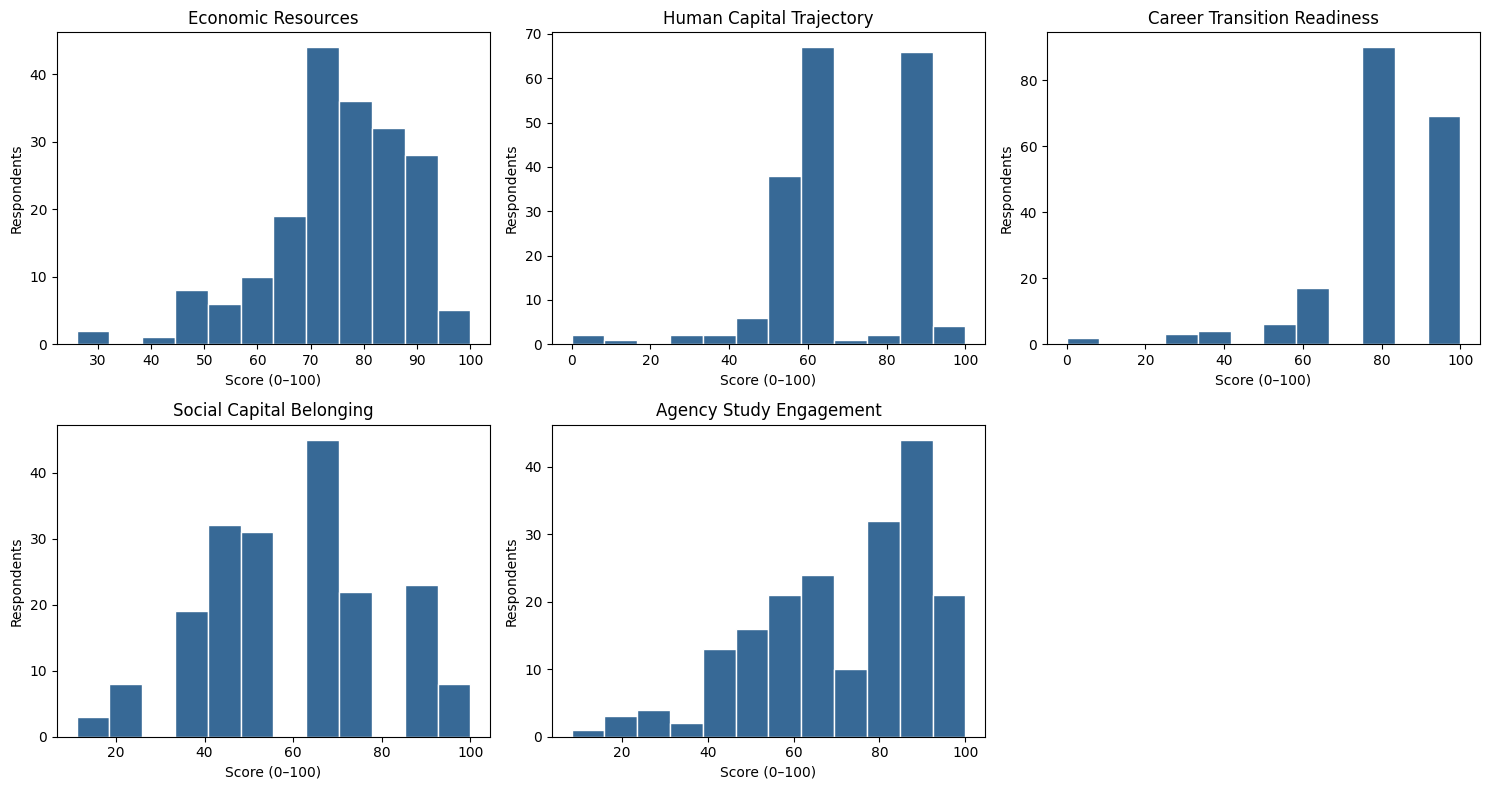

band,high,low,moderate
dimension,,,
agency_study_engagement,121,8,62
career_transition_readiness,159,5,27
economic_resources,151,2,38
human_capital_trajectory,73,5,113
social_capital_belonging,53,11,127


In [7]:
score_summary = score_data[dimension_columns].describe().T
score_summary["missing_rows"] = score_data[dimension_columns].isna().sum()
score_summary["missing_pct"] = 100 * score_data[dimension_columns].isna().mean()
score_summary["coefficient_of_variation"] = score_summary["std"] / score_summary["mean"].replace(0, np.nan)
score_summary.to_csv(OUTPUT_DIR / "branch_d_dimension_score_summary.csv")
display(score_summary)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, dimension in zip(axes.flat, dimension_columns):
    ax.hist(score_data[dimension].dropna(), bins=12, color="#376996", edgecolor="white")
    ax.set(title=dimension.replace("_", " ").title(), xlabel="Score (0–100)", ylabel="Respondents")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

band_counts = []
for dimension in dimension_columns:
    counts = score_data[f"{dimension}__descriptive_band"].value_counts(dropna=False)
    for band, count in counts.items():
        band_counts.append({"dimension": dimension, "band": str(band), "rows": int(count)})
band_distribution = pd.DataFrame(band_counts)
band_distribution.to_csv(OUTPUT_DIR / "branch_d_dimension_band_distribution.csv", index=False)
display(band_distribution.pivot(index="dimension", columns="band", values="rows").fillna(0).astype(int))

## 7. Correlation and component diagnostics

Dimensions should be related enough to describe the same respondents but not so highly correlated that they duplicate one another. Component–score relationships are descriptive for formative indices.

,economic_resources,human_capital_trajectory,career_transition_readiness,social_capital_belonging,agency_study_engagement
economic_resources,1.000000,0.274123,0.158976,0.040643,0.002163
human_capital_trajectory,0.274123,1.000000,0.053223,-0.057904,0.087380
career_transition_readiness,0.158976,0.053223,1.000000,0.105876,0.237823
social_capital_belonging,0.040643,-0.057904,0.105876,1.000000,0.057858
agency_study_engagement,0.002163,0.087380,0.237823,0.057858,1.000000


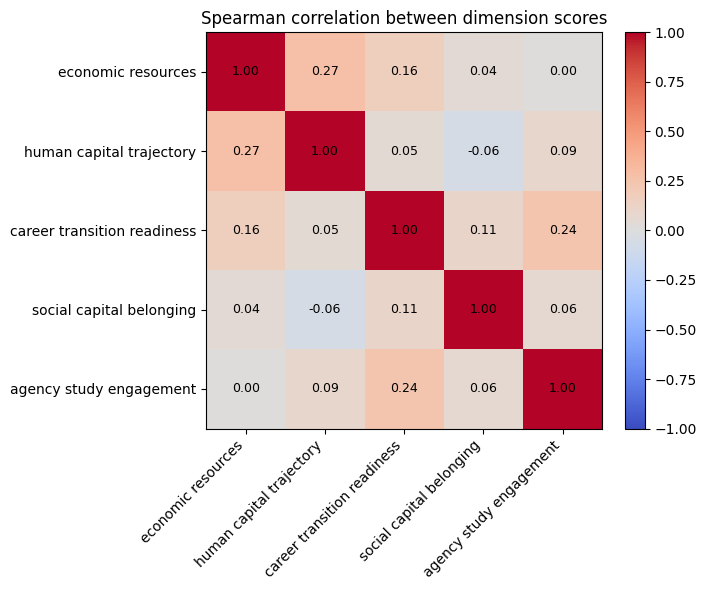

,dimension,component,component_score_spearman,corrected_component_total_spearman,leave_one_out_score_correlation
0,economic_resources,income_resources,0.771489,0.376178,0.876808
1,economic_resources,working_household_share,0.556440,0.152164,0.876653
2,economic_resources,low_household_unemployment,0.499944,0.147596,0.915465
3,economic_resources,freedom_from_primary_earner_burden,0.385911,0.157756,0.957412
4,economic_resources,education_funding_security,0.308002,0.166507,0.973503
5,human_capital_trajectory,current_education_stage,0.413654,0.184673,0.952294
6,human_capital_trajectory,expected_education_level,0.486697,0.113682,0.905157
7,human_capital_trajectory,work_exposure_while_studying,0.856071,0.081689,0.590463
8,career_transition_readiness,transition_plan_present,0.283494,0.048793,0.956004
9,career_transition_readiness,already_searching_for_work,0.621492,0.007495,0.753996


In [8]:
dimension_correlations = score_data[dimension_columns].corr(method="spearman")
dimension_correlations.to_csv(OUTPUT_DIR / "branch_d_dimension_correlations.csv")
display(dimension_correlations)

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(dimension_correlations, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(dimension_columns)), [x.replace("_", " ") for x in dimension_columns], rotation=45, ha="right")
ax.set_yticks(range(len(dimension_columns)), [x.replace("_", " ") for x in dimension_columns])
for i in range(len(dimension_columns)):
    for j in range(len(dimension_columns)):
        ax.text(j, i, f"{dimension_correlations.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(image, ax=ax, fraction=0.046)
ax.set_title("Spearman correlation between dimension scores")
plt.tight_layout()
plt.show()

component_diagnostic_rows = []
for dimension, dimension_components in DIMENSION_COMPONENTS.items():
    full_score = score_data[dimension]
    for component in dimension_components:
        other_components = [x for x in dimension_components if x != component]
        component_series = components[component]
        other_mean = 100 * components[other_components].mean(axis=1, skipna=True)
        component_diagnostic_rows.append({
            "dimension": dimension,
            "component": component,
            "component_score_spearman": component_series.corr(full_score, method="spearman"),
            "corrected_component_total_spearman": component_series.corr(other_mean, method="spearman"),
            "leave_one_out_score_correlation": full_score.corr(other_mean, method="spearman"),
        })
component_diagnostics = pd.DataFrame(component_diagnostic_rows)
component_diagnostics.to_csv(OUTPUT_DIR / "branch_d_component_diagnostics.csv", index=False)
display(component_diagnostics)

## 8. SDT agency reliability diagnostic

Cronbach's alpha is reported only for the three agency/study-engagement items because they are treated as a reflective diagnostic. It is not used to accept or reject formative economic, human-capital, career or social-capital indices.

In [9]:
def cronbach_alpha(frame):
    complete = frame.dropna()
    k = complete.shape[1]
    if k < 2 or len(complete) < 3:
        return np.nan, len(complete)
    item_variances = complete.var(axis=0, ddof=1).sum()
    total_variance = complete.sum(axis=1).var(ddof=1)
    if total_variance == 0:
        return np.nan, len(complete)
    return float(k / (k - 1) * (1 - item_variances / total_variance)), len(complete)


agency_components = DIMENSION_COMPONENTS["agency_study_engagement"]
agency_alpha, agency_complete_rows = cronbach_alpha(components[agency_components])
reliability_diagnostics = pd.DataFrame([{
    "dimension": "agency_study_engagement",
    "diagnostic": "Cronbach alpha",
    "value": agency_alpha,
    "complete_rows": agency_complete_rows,
    "interpretation_note": "Diagnostic only: motivation, autonomy and competence are theoretically distinct SDT constructs.",
}])
reliability_diagnostics.to_csv(OUTPUT_DIR / "branch_d_reliability_diagnostics.csv", index=False)
display(reliability_diagnostics)

,dimension,diagnostic,value,complete_rows,interpretation_note
0,agency_study_engagement,Cronbach alpha,0.550717,191,"Diagnostic only: motivation, autonomy and comp..."


## 9. Integrated-clustering readiness checks

This section does not run clustering. It determines whether the five dimension scores are sufficiently complete and variable to enter the Level 2 notebook.

In [10]:
readiness_rows = []
for dimension in dimension_columns:
    series = score_data[dimension]
    readiness_rows.append({
        "dimension": dimension,
        "coverage_pct": 100 * series.notna().mean(),
        "standard_deviation": series.std(),
        "unique_scores": series.nunique(dropna=True),
        "coverage_pass_90pct": series.notna().mean() >= 0.90,
        "variation_pass_std5": series.std() >= 5,
    })
readiness = pd.DataFrame(readiness_rows)
readiness["ready_for_integrated_clustering"] = (
    readiness["coverage_pass_90pct"] & readiness["variation_pass_std5"]
)
readiness.to_csv(OUTPUT_DIR / "branch_d_dimension_readiness.csv", index=False)
display(readiness)

complete_dimension_rows = score_data[dimension_columns].notna().all(axis=1)
print("Respondents with all five dimension scores:", int(complete_dimension_rows.sum()), "/", len(score_data))

,dimension,coverage_pct,standard_deviation,unique_scores,coverage_pass_90pct,variation_pass_std5,ready_for_integrated_clustering
0,economic_resources,100.0,12.772689,56,True,True,True
1,human_capital_trajectory,100.0,19.242766,18,True,True,True
2,career_transition_readiness,100.0,18.931975,8,True,True,True
3,social_capital_belonging,100.0,20.693901,9,True,True,True
4,agency_study_engagement,100.0,20.291435,28,True,True,True


Respondents with all five dimension scores: 191 / 191


## 10. Save the dimension-engineering summary

In [11]:
summary = {
    "cohort": {
        "branch": "D",
        "routing_source": "translated_final_active_branch",
        "records": int(len(values)),
    },
    "method": {
        "dimensions": dimension_columns,
        "component_count": int(len(component_columns)),
        "minimum_component_coverage": MIN_COMPONENT_COVERAGE,
        "aggregation": "Equal-weight mean of available normalized components when coverage threshold is met",
        "score_range": "0–100; higher means more of the named dimension",
    },
    "coverage": {
        row.dimension: {
            "scored_rows": int(row.scored_rows),
            "coverage_pct": float(row.score_coverage_pct),
        }
        for row in dimension_coverage.itertuples()
    },
    "complete_five_dimension_rows": int(score_data[dimension_columns].notna().all(axis=1).sum()),
    "agency_cronbach_alpha_diagnostic": None if pd.isna(agency_alpha) else float(agency_alpha),
    "dimensions_passing_readiness_checks": readiness.loc[
        readiness["ready_for_integrated_clustering"], "dimension"
    ].tolist(),
    "status": (
        "Ready for Level 2 integrated clustering"
        if readiness["ready_for_integrated_clustering"].all()
        else "Review dimensions failing coverage or variation checks before Level 2 clustering"
    ),
}

with open(OUTPUT_DIR / "branch_d_dimension_summary.json", "w", encoding="utf-8") as handle:
    json.dump(summary, handle, indent=2)

display(pd.Series({
    "records": summary["cohort"]["records"],
    "components": summary["method"]["component_count"],
    "complete five-score rows": summary["complete_five_dimension_rows"],
    "agency alpha (diagnostic)": summary["agency_cronbach_alpha_diagnostic"],
    "dimensions passing readiness": len(summary["dimensions_passing_readiness_checks"]),
    "status": summary["status"],
}).to_frame("result"))

,result
records,191
components,19
complete five-score rows,191
agency alpha (diagnostic),0.550717
dimensions passing readiness,5
status,Ready for Level 2 integrated clustering


## Decision checkpoint

Do not proceed automatically merely because five score columns exist. Review:

1. The component manifest and every theory-defined mapping.
2. Low-variation components and ceiling/floor effects.
3. Missingness and score coverage.
4. Whether the five dimensions remain conceptually distinct.
5. The SDT reliability diagnostic without treating alpha as the sole validity criterion.
6. The study-field/sector alignment crosswalk with an NYSC or subject-matter expert.

After approval, the next notebook should standardize these five scores and evaluate integrated Branch D K-Means solutions for `k=3–5`, with K-Medoids as a robustness comparison.